In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re

ps2 = pd.read_csv('PS2.txt', sep='\t', header=None)
fs1 = pd.read_csv('FS1.txt', sep='\t', header=None)
profile = pd.read_csv('profile.txt', sep='\t', header=None,
                      names=['cooler','valve','pump_leak','accumulator','stable'])
print(ps2.describe(), fs1.describe(), profile.describe())

              0            1            2            3            4     \
count  2205.000000  2205.000000  2205.000000  2205.000000  2205.000000   
mean    123.362422   123.364358   123.339202   122.831868   121.808503   
std       3.701729     3.694412     3.700527     3.819922     3.746546   
min     119.610000   119.630000   118.920000   118.650000   115.830000   
25%     121.630000   121.670000   121.660000   120.560000   118.830000   
50%     123.040000   123.040000   123.010000   122.620000   122.060000   
75%     125.100000   125.100000   125.090000   124.830000   124.480000   
max     165.480000   165.260000   165.530000   165.690000   160.570000   

              5            6            7            8            9     ...  \
count  2205.000000  2205.000000  2205.000000  2205.000000  2205.000000  ...   
mean    120.693455   104.294819    64.491438    35.220531    27.355589  ...   
std       3.541433     9.616892     8.636717     3.792106     3.286553  ...   
min      97.28900

In [3]:
from scipy import stats

def extract(df, name, n_win=6):
    X = df.values
    f = {
        f'{name}_mean': X.mean(1),   f'{name}_std': X.std(1),
        f'{name}_min': X.min(1),     f'{name}_max': X.max(1),
        f'{name}_median': np.median(X, 1),
        f'{name}_q25': np.percentile(X, 25, 1), f'{name}_q75': np.percentile(X, 75, 1),
        f'{name}_ptp': np.ptp(X, 1), f'{name}_rms': np.sqrt((X**2).mean(1)),
        f'{name}_skew': stats.skew(X, 1), f'{name}_kurt': stats.kurtosis(X, 1),
        f'{name}_slope': np.polyfit(np.arange(X.shape[1]), X.T, 1)[0],
    }
    for i, w in enumerate(np.array_split(X, n_win, axis=1)):   # 6 fenêtres de 10 s
        f[f'{name}_w{i}_mean'] = w.mean(1)
        f[f'{name}_w{i}_std']  = w.std(1)
    return pd.DataFrame(f)

X = pd.concat([extract(ps2, 'PS2'), extract(fs1, 'FS1')], axis=1)
print(X.shape)   

(2205, 48)


In [4]:
y = (profile['valve'] == 100).astype(int)
X_train, X_test = X.iloc[:2000], X.iloc[2000:]
y_train, y_test = y.iloc[:2000], y.iloc[2000:]

In [5]:
display(profile.describe())
display(X_train.describe().T)
print(profile['valve'].value_counts())

,cooler,valve,pump_leak,accumulator,stable
count,2205.000000,2205.000000,2205.000000,2205.000000,2205.000000
mean,41.240816,90.693878,0.669388,107.199546,0.342857
std,42.383143,10.681802,0.817233,16.435848,0.474772
min,3.000000,73.000000,0.000000,90.000000,0.000000
25%,3.000000,80.000000,0.000000,90.000000,0.000000
50%,20.000000,100.000000,0.000000,100.000000,0.000000
75%,100.000000,100.000000,1.000000,130.000000,1.000000
max,100.000000,100.000000,2.000000,130.000000,1.000000


,count,mean,std,min,25%,50%,75%,max
PS2_mean,2000.0,1.093929e+02,5.234843,104.406307,106.834642,107.558399,109.380006,131.589089
PS2_std,2000.0,4.777506e+01,3.431611,45.203186,46.152657,46.639318,47.158258,59.548285
PS2_min,2000.0,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
PS2_max,2000.0,1.664498e+02,0.998311,155.040000,166.100000,166.570000,167.020000,167.740000
PS2_median,2000.0,1.285538e+02,3.619176,124.445000,127.025000,127.810000,129.875000,165.400000
PS2_q25,2000.0,1.179968e+02,1.715097,112.840000,116.480000,117.930000,120.060000,120.690000
PS2_q75,2000.0,1.327281e+02,12.019769,125.040000,127.645000,128.300000,130.470000,165.560000
PS2_ptp,2000.0,1.664498e+02,0.998311,155.040000,166.100000,166.570000,167.020000,167.740000
PS2_rms,2000.0,1.193750e+02,6.167282,114.004268,116.473327,117.186905,119.122161,144.200980
PS2_skew,2000.0,-1.770610e+00,0.146186,-1.842342,-1.835386,-1.830244,-1.793605,-1.317604


valve
100    1125
73      360
80      360
90      360
Name: count, dtype: int64


In [6]:
print(ps2.isna().sum().sum(), fs1.isna().sum().sum(), profile.isna().sum().sum())

0 0 0


In [7]:
Q1, Q3 = X_train.quantile(.25), X_train.quantile(.75)
IQR = Q3 - Q1
out = ((X_train < Q1 - 1.5*IQR) | (X_train > Q3 + 1.5*IQR)).sum().sort_values(ascending=False)
print(out.head(15))

FS1_w4_std     539
FS1_w1_std     419
FS1_w0_mean    308
FS1_w0_std     305
FS1_std        263
PS2_mean       240
PS2_q75        240
PS2_std        240
PS2_w3_mean    240
PS2_w3_std     240
PS2_w2_std     240
PS2_rms        240
PS2_slope      240
PS2_kurt       240
PS2_skew       240
dtype: int64


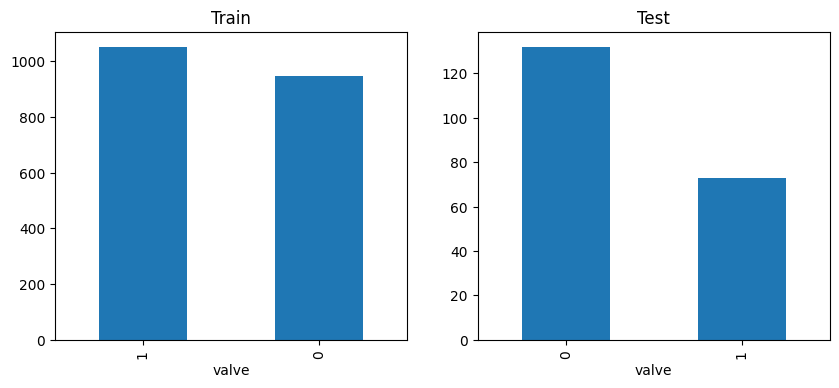

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
y_train.value_counts().plot.bar(ax=ax[0], title='Train')
y_test.value_counts().plot.bar(ax=ax[1], title='Test')
plt.show()

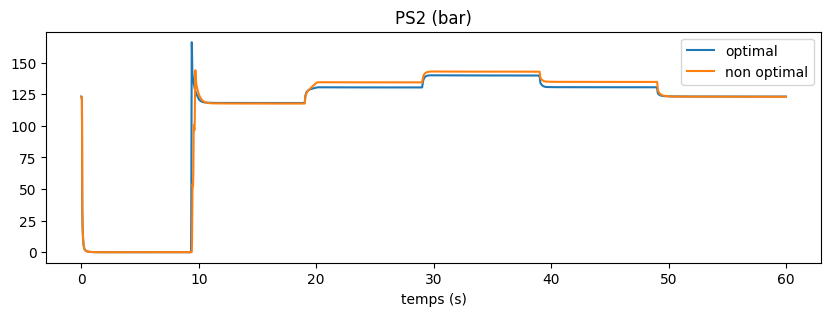

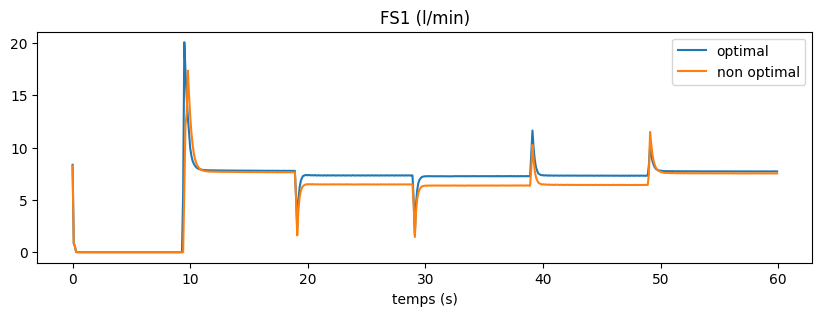

In [9]:
for sig, name, hz in [(ps2, 'PS2 (bar)', 100), (fs1, 'FS1 (l/min)', 10)]:
    t = np.arange(sig.shape[1]) / hz
    tr = sig.iloc[:2000]
    plt.figure(figsize=(10, 3))
    plt.plot(t, tr[y_train == 1].mean(), label='optimal')
    plt.plot(t, tr[y_train == 0].mean(), label='non optimal')
    plt.xlabel('temps (s)'); plt.title(name); plt.legend(); plt.show()

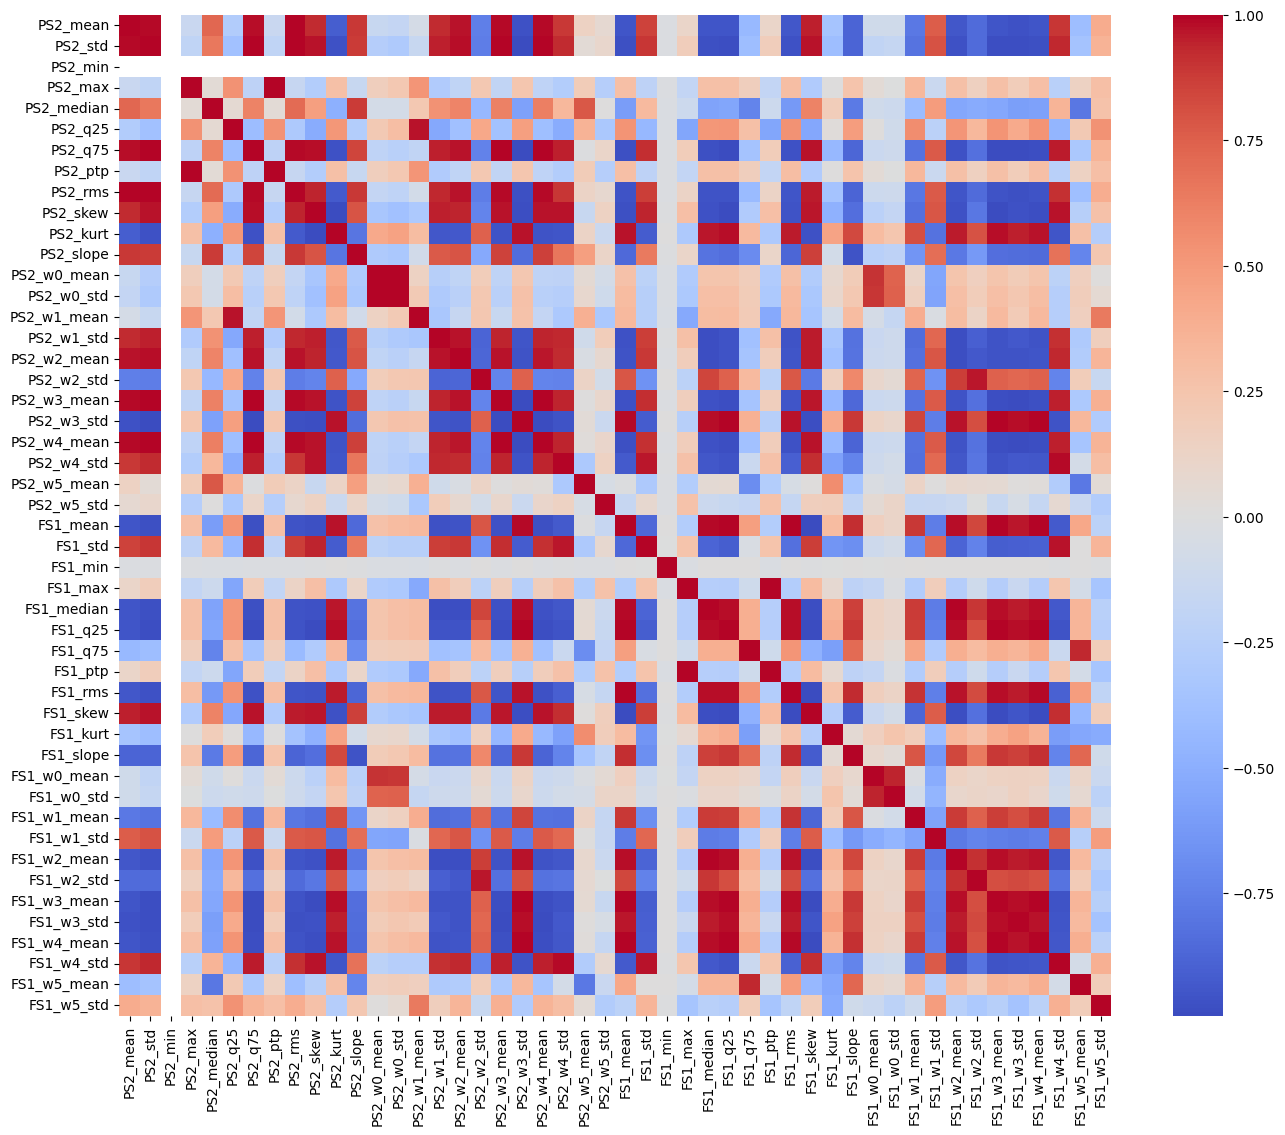

PS2_w0_mean    0.800229
PS2_w0_std     0.758500
FS1_w0_mean    0.589652
FS1_w1_std    -0.464220
FS1_w0_std     0.349644
PS2_kurt       0.342991
PS2_skew      -0.270045
FS1_skew      -0.258678
PS2_slope     -0.253538
FS1_rms        0.238537
FS1_mean       0.230846
PS2_std       -0.224583
FS1_w4_mean    0.210756
FS1_q25        0.209943
FS1_w3_mean    0.209065
dtype: float64


c:\Users\yogog\AppData\Local\Programs\Python\Python313\Lib\site-packages\numpy\lib\_function_base_impl.py:3065: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
c:\Users\yogog\AppData\Local\Programs\Python\Python313\Lib\site-packages\numpy\lib\_function_base_impl.py:3066: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


In [10]:
corr = X_train.corr()
plt.figure(figsize=(16, 13))
sns.heatmap(corr, cmap='coolwarm', center=0)
plt.show()

print(X_train.corrwith(y_train).sort_values(key=abs, ascending=False).head(15))

In [11]:
from sklearn.feature_selection import VarianceThreshold, mutual_info_classif, f_classif
from sklearn.ensemble import RandomForestClassifier

# 1. Variance quasi nulle
vt = VarianceThreshold(1e-6).fit(X_train)
X_sel = X_train.loc[:, vt.get_support()]

# 2. Filtre de redondance : on retire une feature d'une paire si |r| > 0.95
c = X_sel.corr().abs()
upper = c.where(np.triu(np.ones(c.shape), 1).astype(bool))
drop = [col for col in upper if (upper[col] > 0.95).any()]
X_sel = X_sel.drop(columns=drop)
print(len(drop), 'retirées ->', X_sel.shape[1], 'restantes')

# 3. Scores univariés + importance d'une Random Forest
scores = pd.DataFrame({
    'ANOVA_F': f_classif(X_sel, y_train)[0],
    'MutualInfo': mutual_info_classif(X_sel, y_train, random_state=0),
    'RF_importance': RandomForestClassifier(300, random_state=0).fit(X_sel, y_train).feature_importances_,
}, index=X_sel.columns)
display(scores.sort_values('MutualInfo', ascending=False))

28 retirées -> 18 restantes


,ANOVA_F,MutualInfo,RF_importance
PS2_w0_mean,3557.658766,0.672443,0.425203
FS1_w1_std,548.845538,0.466606,0.185502
FS1_w0_mean,1064.957978,0.366797,0.117965
PS2_mean,37.384348,0.318659,0.018887
PS2_slope,137.258038,0.316933,0.057035
FS1_w1_mean,58.815426,0.289638,0.026797
FS1_q75,71.311229,0.232772,0.038040
FS1_w5_mean,59.437805,0.224113,0.036572
PS2_w5_mean,0.406212,0.212896,0.006287
PS2_q25,26.524177,0.200496,0.007391


In [12]:
features = scores.rank(ascending=False).mean(1).sort_values().index[:20].tolist()
X_train_f, X_test_f = X_train[features], X_test[features]

In [13]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

RS = 42
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RS)

print(len(features), 'variables :', features)
print('Train :', X_train_f.shape, '| Test :', X_test_f.shape)

18 variables : ['PS2_w0_mean', 'FS1_w1_std', 'FS1_w0_mean', 'PS2_slope', 'FS1_q75', 'FS1_w5_mean', 'FS1_w1_mean', 'FS1_w0_std', 'PS2_mean', 'PS2_q25', 'PS2_w2_std', 'FS1_max', 'FS1_kurt', 'PS2_median', 'PS2_w5_mean', 'PS2_max', 'FS1_w5_std', 'PS2_w5_std']
Train : (2000, 18) | Test : (205, 18)


histogrammes et boxplots

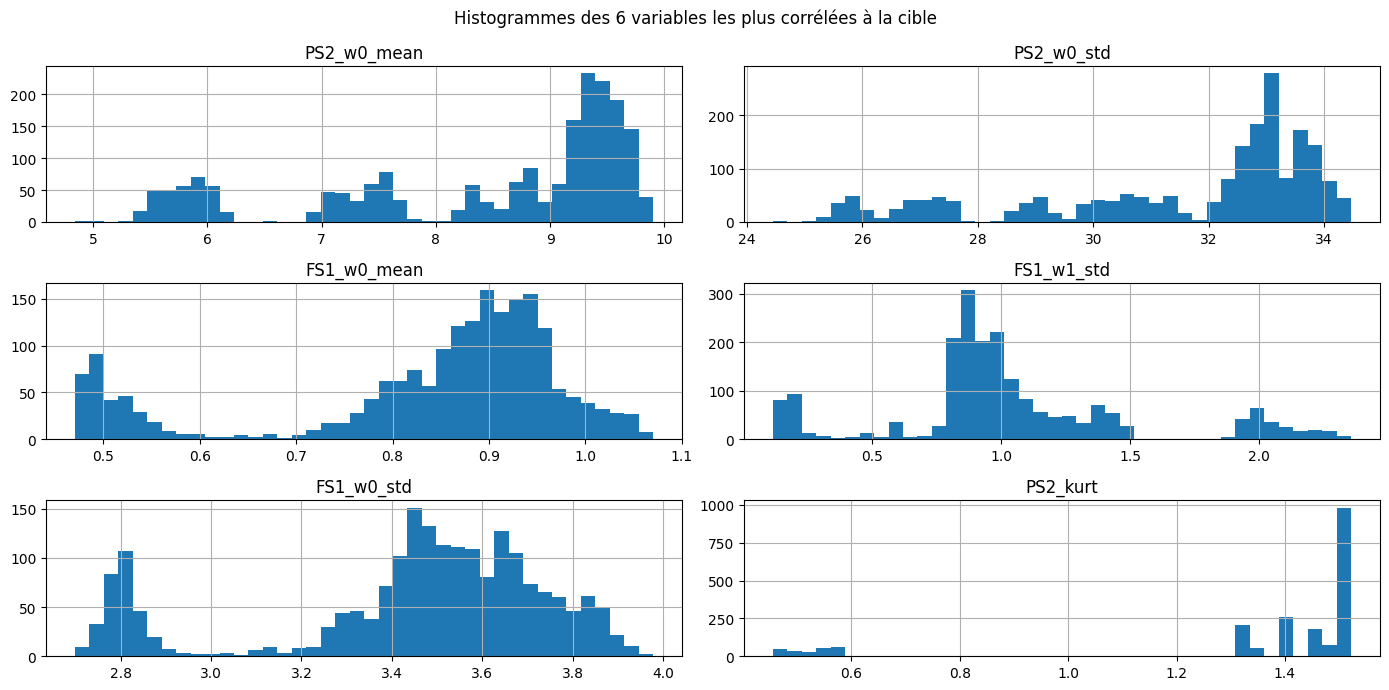

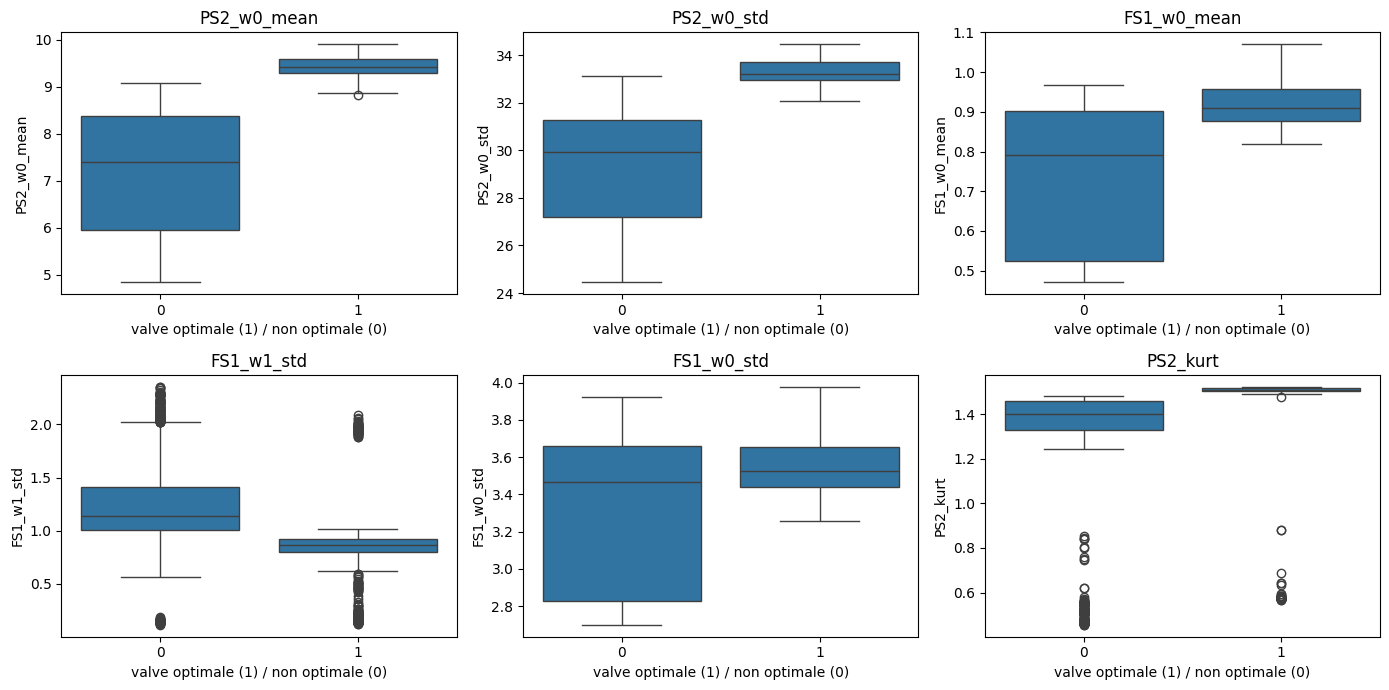

In [14]:
X_var = X_train.loc[:, X_train.std() > 0]          # retire PS2_min (constante)
top6 = X_var.corrwith(y_train).abs().sort_values(ascending=False).index[:6].tolist()

# Histogrammes
X_train[top6].hist(bins=40, figsize=(14, 7))
plt.suptitle('Histogrammes des 6 variables les plus corrélées à la cible')
plt.tight_layout(); plt.show()

# Boxplots par classe
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, f in zip(axes.ravel(), top6):
    sns.boxplot(x=y_train, y=X_train[f], ax=ax)
    ax.set_title(f); ax.set_xlabel('valve optimale (1) / non optimale (0)')
plt.tight_layout(); plt.show()

In [15]:
import time, os, warnings
import joblib
warnings.filterwarnings('ignore', category=FutureWarning)
os.environ['PYTHONWARNINGS'] = 'ignore'   # propage aux processus parallèles (n_jobs=-1)
from scipy.stats import loguniform, randint
from sklearn.model_selection import cross_val_predict, cross_val_score, GridSearchCV, RandomizedSearchCV, learning_curve
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.ensemble import GradientBoostingClassifier, VotingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report, roc_curve)

def make_pipe(clf):
    return Pipeline([('sc', StandardScaler()), ('clf', clf)])

models = {
    'LogReg':       make_pipe(LogisticRegression(max_iter=2000, random_state=RS)),
    'kNN':          make_pipe(KNeighborsClassifier()),
    'DecisionTree': make_pipe(DecisionTreeClassifier(random_state=RS)),
    'NaiveBayes':   make_pipe(GaussianNB()),
    'SVM (RBF)':    make_pipe(SVC(probability=True, random_state=RS)),
    'RandomForest': make_pipe(RandomForestClassifier(300, random_state=RS)),
    'GradBoosting': make_pipe(GradientBoostingClassifier(random_state=RS)),
}
models['Voting (soft)'] = VotingClassifier(
    [('lr', models['LogReg']), ('svm', models['SVM (RBF)']), ('rf', models['RandomForest'])],
    voting='soft')
print(list(models))

['LogReg', 'kNN', 'DecisionTree', 'NaiveBayes', 'SVM (RBF)', 'RandomForest', 'GradBoosting', 'Voting (soft)']


Tableau comparatif des modèles en croos-fold

In [16]:
scoring = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']
rows = []
for name, m in models.items():
    r = cross_validate(m, X_train_f, y_train, cv=cv, scoring=scoring,
                       return_train_score=True, n_jobs=-1)
    rows.append({'modèle': name,
                 **{s: r[f'test_{s}'].mean() for s in scoring},
                 'f1_std': r['test_f1'].std(),
                 'f1_train': r['train_f1'].mean(),
                 'écart train-CV': r['train_f1'].mean() - r['test_f1'].mean()})
baseline = pd.DataFrame(rows).set_index('modèle').sort_values('f1', ascending=False)
display(baseline.round(4))

,accuracy,precision,recall,f1,roc_auc,f1_std,f1_train,écart train-CV
modèle,,,,,,,,
Voting (soft),1.0000,1.0000,1.0000,1.0000,1.0000,0.0000,1.0000,0.0000
LogReg,0.9985,0.9972,1.0000,0.9986,1.0000,0.0019,0.9991,0.0005
RandomForest,0.9980,1.0000,0.9962,0.9981,1.0000,0.0023,1.0000,0.0019
GradBoosting,0.9960,0.9972,0.9953,0.9962,0.9975,0.0024,1.0000,0.0038
SVM (RBF),0.9960,0.9981,0.9943,0.9962,0.9998,0.0019,0.9988,0.0026
DecisionTree,0.9950,0.9962,0.9943,0.9952,0.9950,0.0033,1.0000,0.0048
kNN,0.9900,0.9915,0.9895,0.9905,0.9997,0.0015,0.9957,0.0052
NaiveBayes,0.8805,0.8541,0.9335,0.8916,0.9776,0.0170,0.8921,0.0004


matrices de confusion et courbes ROC

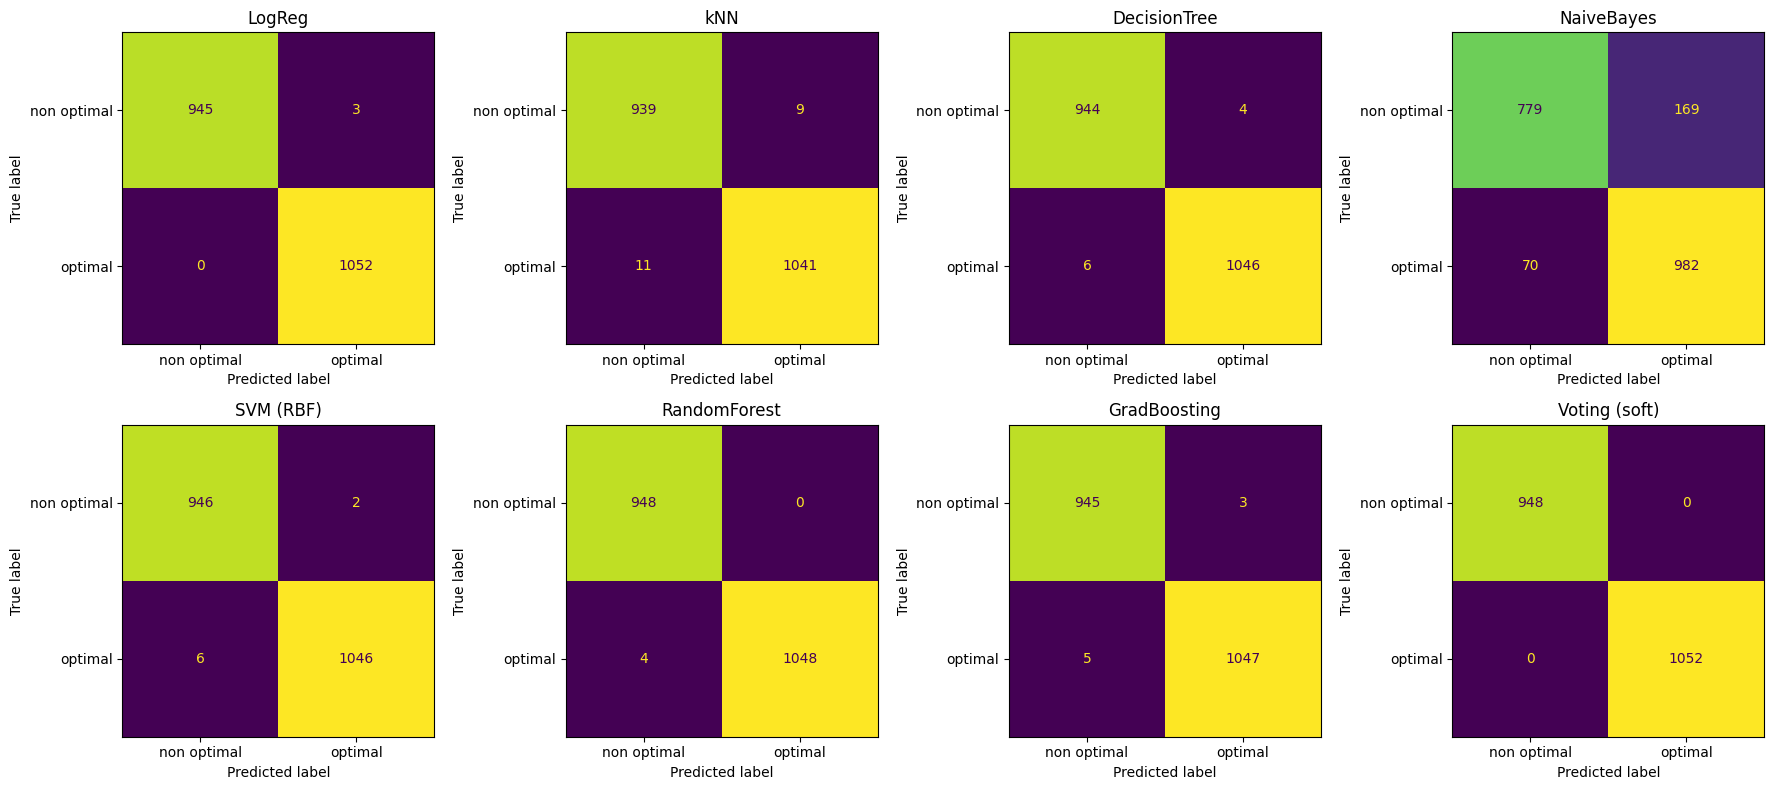

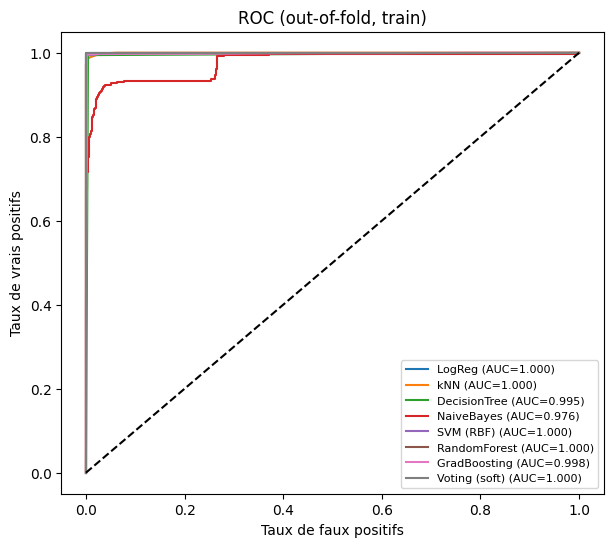

In [18]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
roc_fig, roc_ax = plt.subplots(figsize=(7, 6))
for ax, (name, m) in zip(axes.ravel(), models.items()):
    proba = cross_val_predict(m, X_train_f, y_train, cv=cv, method='predict_proba', n_jobs=-1)[:, 1]
    pred = (proba >= 0.5).astype(int)
    ConfusionMatrixDisplay(confusion_matrix(y_train, pred),
                           display_labels=['non optimal', 'optimal']).plot(ax=ax, colorbar=False)
    ax.set_title(name)
    fpr, tpr, _ = roc_curve(y_train, proba)
    roc_ax.plot(fpr, tpr, label=f'{name} (AUC={roc_auc_score(y_train, proba):.3f})')
roc_ax.plot([0, 1], [0, 1], 'k--')
roc_ax.set_xlabel('Taux de faux positifs'); roc_ax.set_ylabel('Taux de vrais positifs')
roc_ax.set_title('ROC (out-of-fold, train)'); roc_ax.legend(fontsize=8)
fig.tight_layout(); plt.show()

optimisation des hyperparamètres

grid search et randaom search


In [19]:
searches = {
    # Grid Search : petits espaces, recherche exhaustive
    'LogReg': GridSearchCV(models['LogReg'],
        {'clf__C': [0.01, 0.1, 1, 10, 100]},
        scoring='f1', cv=cv, n_jobs=-1),
    'SVM (RBF)': GridSearchCV(models['SVM (RBF)'],
        {'clf__C': [0.1, 1, 10, 100], 'clf__gamma': ['scale', 0.001, 0.01, 0.1]},
        scoring='f1', cv=cv, n_jobs=-1),
    'kNN': GridSearchCV(models['kNN'],
        {'clf__n_neighbors': [3, 5, 7, 11, 15], 'clf__weights': ['uniform', 'distance']},
        scoring='f1', cv=cv, n_jobs=-1),
    # Random Search : espaces plus grands
    'DecisionTree': RandomizedSearchCV(models['DecisionTree'],
        {'clf__max_depth': randint(2, 15), 'clf__min_samples_leaf': randint(1, 20),
         'clf__criterion': ['gini', 'entropy']},
        n_iter=30, scoring='f1', cv=cv, n_jobs=-1, random_state=RS),
    'RandomForest': RandomizedSearchCV(models['RandomForest'],
        {'clf__n_estimators': randint(100, 500), 'clf__max_depth': [None, 5, 10, 20],
         'clf__min_samples_leaf': randint(1, 10), 'clf__max_features': ['sqrt', 'log2']},
        n_iter=20, scoring='f1', cv=cv, n_jobs=-1, random_state=RS),
    'GradBoosting': RandomizedSearchCV(models['GradBoosting'],
        {'clf__n_estimators': randint(100, 400), 'clf__learning_rate': loguniform(0.01, 0.3),
         'clf__max_depth': randint(2, 5), 'clf__subsample': [0.7, 0.85, 1.0]},
        n_iter=20, scoring='f1', cv=cv, n_jobs=-1, random_state=RS),
}

rows, tuned = [], {}
for name, s in searches.items():
    t0 = time.time()
    s.fit(X_train_f, y_train)
    tuned[name] = s.best_estimator_
    rows.append({'modèle': name,
                 'type': type(s).__name__,
                 'f1_CV_avant': baseline.loc[name, 'f1'],
                 'f1_CV_après': s.best_score_,
                 'temps (s)': round(time.time() - t0, 1),
                 'meilleurs params': s.best_params_})

# Voting reconstruit avec les modèles optimisés
tuned['Voting (soft)'] = VotingClassifier(
    [('lr', tuned['LogReg']), ('svm', tuned['SVM (RBF)']), ('rf', tuned['RandomForest'])],
    voting='soft').fit(X_train_f, y_train)

tuning = pd.DataFrame(rows).set_index('modèle')
pd.set_option('display.max_colwidth', None)
display(tuning)

,type,f1_CV_avant,f1_CV_après,temps (s),meilleurs params
modèle,,,,,
LogReg,GridSearchCV,0.998579,1.000000,0.1,{'clf__C': 10}
SVM (RBF),GridSearchCV,0.996195,0.999525,2.0,"{'clf__C': 10, 'clf__gamma': 0.1}"
kNN,GridSearchCV,0.990492,0.995274,0.2,"{'clf__n_neighbors': 3, 'clf__weights': 'distance'}"
DecisionTree,RandomizedSearchCV,0.995249,0.996675,0.3,"{'clf__criterion': 'entropy', 'clf__max_depth': 9, 'clf__min_samples_leaf': 3}"
RandomForest,RandomizedSearchCV,0.998091,0.998091,10.3,"{'clf__max_depth': 20, 'clf__max_features': 'sqrt', 'clf__min_samples_leaf': 1, 'clf__n_estimators': 158}"
GradBoosting,RandomizedSearchCV,0.996197,0.997150,18.5,"{'clf__learning_rate': 0.07725378389307355, 'clf__max_depth': 4, 'clf__n_estimators': 249, 'clf__subsample': 0.7}"


In [20]:
rows = []
for name, m in tuned.items():
    r = cross_validate(m, X_train_f, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    rows.append({'modèle': name, **{s: r[f'test_{s}'].mean() for s in scoring}, 'f1_std': r['test_f1'].std()})
cv_tuned = pd.DataFrame(rows).set_index('modèle').sort_values('f1', ascending=False)
display(cv_tuned.round(4))

,accuracy,precision,recall,f1,roc_auc,f1_std
modèle,,,,,,
LogReg,1.0000,1.0000,1.0000,1.0000,1.0000,0.0000
Voting (soft),1.0000,1.0000,1.0000,1.0000,1.0000,0.0000
SVM (RBF),0.9995,1.0000,0.9991,0.9995,1.0000,0.0010
RandomForest,0.9980,1.0000,0.9962,0.9981,1.0000,0.0023
GradBoosting,0.9970,0.9972,0.9971,0.9971,0.9990,0.0028
DecisionTree,0.9965,0.9972,0.9962,0.9967,0.9965,0.0032
kNN,0.9950,0.9934,0.9972,0.9953,0.9999,0.0039


,accuracy,precision,recall,f1,roc_auc
modèle,,,,,
LogReg,1.0000,1.0000,1.0,1.0000,1.0000
SVM (RBF),1.0000,1.0000,1.0,1.0000,1.0000
Voting (soft),1.0000,1.0000,1.0,1.0000,1.0000
RandomForest,0.9854,0.9605,1.0,0.9799,1.0000
GradBoosting,0.9659,0.9125,1.0,0.9542,0.9971
DecisionTree,0.9220,0.8202,1.0,0.9012,0.9394
kNN,0.9073,0.7935,1.0,0.8848,0.9470


Modèle retenu : LogReg
              precision    recall  f1-score   support

non optimale       1.00      1.00      1.00       132
    optimale       1.00      1.00      1.00        73

    accuracy                           1.00       205
   macro avg       1.00      1.00      1.00       205
weighted avg       1.00      1.00      1.00       205



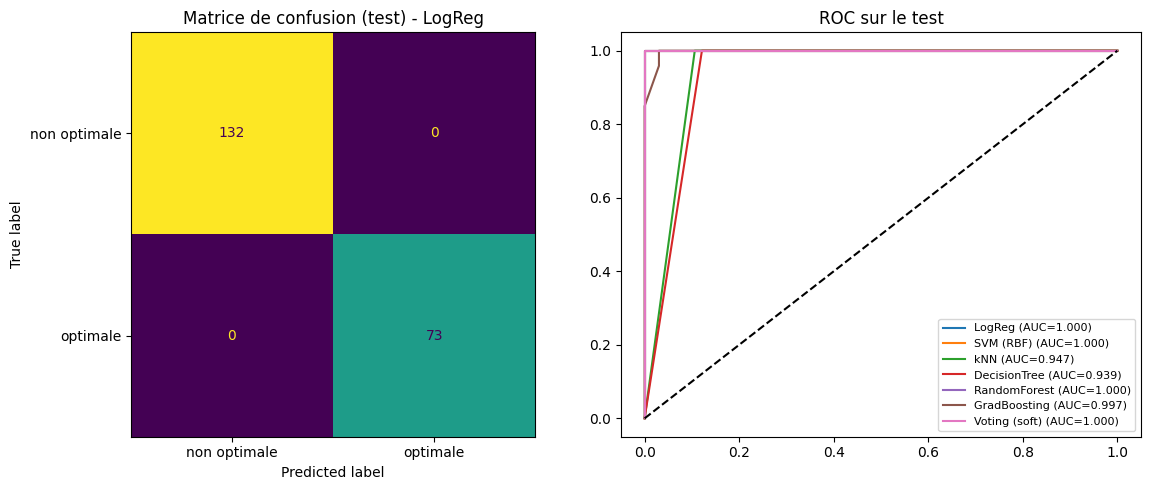

In [21]:
rows = []
for name, m in tuned.items():
    pred = m.predict(X_test_f)
    proba = m.predict_proba(X_test_f)[:, 1]
    rows.append({'modèle': name,
                 'accuracy': accuracy_score(y_test, pred),
                 'precision': precision_score(y_test, pred),
                 'recall': recall_score(y_test, pred),
                 'f1': f1_score(y_test, pred),
                 'roc_auc': roc_auc_score(y_test, proba)})
test_res = pd.DataFrame(rows).set_index('modèle').sort_values('f1', ascending=False)
display(test_res.round(4))

best_name = cv_tuned['f1'].idxmax()          # choix basé sur la CV, PAS sur le test
best = tuned[best_name]
print('Modèle retenu :', best_name)
print(classification_report(y_test, best.predict(X_test_f), target_names=['non optimale', 'optimale']))

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay.from_estimator(best, X_test_f, y_test,
    display_labels=['non optimale', 'optimale'], ax=ax[0], colorbar=False)
ax[0].set_title(f'Matrice de confusion (test) - {best_name}')
for name, m in tuned.items():
    fpr, tpr, _ = roc_curve(y_test, m.predict_proba(X_test_f)[:, 1])
    ax[1].plot(fpr, tpr, label=f'{name} (AUC={roc_auc_score(y_test, m.predict_proba(X_test_f)[:,1]):.3f})')
ax[1].plot([0, 1], [0, 1], 'k--'); ax[1].set_title('ROC sur le test'); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()